# Notebook 17: Quantified interpretability, NMF against PCA

Addresses **Reviewer 1 #7**: *the comparison against PCA and conventional univariate analysis
is useful, but the benefits of NMF in terms of component interpretability are largely
qualitative; a more systematic comparison should be included.*

It also supplies the numbers behind the argument made in response to **R1.1** and **R2.1**,
that non-negativity buys legibility and sign-definiteness rather than sensitivity.

## What can and cannot be measured

Interpretability is not fully reducible to a metric, and this notebook does not pretend
otherwise. A reader who finds signed contrasts perfectly interpretable will not be moved by a
Gini coefficient. What the measurements can establish is the narrower claim the manuscript
actually needs: that the NMF components are more spatially and spectrally concentrated than
the principal axes, and that they require no cancellation to describe.

One part of the claim is not a matter of degree at all, and Part D demonstrates it
numerically rather than arguing it. In a signed factorisation the sign of a component is
arbitrary: negating both a principal axis and its scores leaves the reconstruction identical,
while reversing the direction of that component's reported association with sex. So "higher in
women on one component, higher in men on another" is not a statement about the data in a PCA
basis. In a non-negative basis it is. That is why the manuscript's central finding - two
contributions of opposing sign - is expressible under NMF and not under PCA, and it is the
strongest available answer to this point.

## Structure

| Part | Measures |
|---|---|
| **A** | Concentration: features and channels needed to reach a fixed share of each component's weight |
| **B** | Sparsity: Gini coefficient and normalised entropy of the loading vectors |
| **C** | Sign structure: the share of each principal axis's weight carried by negative loadings, which has no counterpart under NMF |
| **D** | Sign arbitrariness demonstrated: reconstruction unchanged, reported association reversed |
| **E** | The cost of the constraint: reconstruction and variance explained at matched dimensionality |

## Inputs and outputs

Inputs: `feature_matrix.csv`, `metadata.csv`, `nmf_H.csv`, `nmf_W.csv`,
`posthoc_per_component.csv`

CSVs: `nb17_concentration.csv`, `nb17_sparsity.csv`, `nb17_sign_structure.csv`,
`nb17_sign_flip_demo.csv`, `nb17_constraint_cost.csv`
Figure: `nb17_fig_interpretability.png` — 300 dpi
Summary: `nb17_summary.txt`

## Setup

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from sklearn.decomposition import PCA
from statsmodels.stats.multitest import multipletests

warnings.filterwarnings("ignore")

PROJECT_ROOT = Path(".").resolve().parent
OUTPUT_DIR = PROJECT_ROOT / "outputs"

CHANNELS = ["AF3", "F7", "F3", "FC5", "T7", "P7", "O1",
            "O2", "P8", "T8", "FC6", "F4", "F8", "AF4"]
FREQ_BANDS = ["Theta", "Alpha", "BetaL", "BetaH", "Gamma"]

PUBLISHED_K = 5
MASS_SHARES = [0.5, 0.8, 0.9]      # shares of component weight to reach
FDR_ALPHA = 0.05
PCA_SEED = 0
SEX_COL = "Gender"

print("Comparing the published NMF basis with a principal-component basis at k = 5")
print("on the same feature matrix. Runtime: under a minute; no permutation testing here.")

Comparing the published NMF basis with a principal-component basis at k = 5
on the same feature matrix. Runtime: under a minute; no permutation testing here.


## Load inputs and fit the PCA basis

In [2]:
feature_matrix = pd.read_csv(OUTPUT_DIR / "feature_matrix.csv", index_col="participant_id")
metadata = (pd.read_csv(OUTPUT_DIR / "metadata.csv")
            .set_index("participant_id")
            .reindex(feature_matrix.index))
H_ref = pd.read_csv(OUTPUT_DIR / "nmf_H.csv", index_col=0)
W_ref = pd.read_csv(OUTPUT_DIR / "nmf_W.csv", index_col="participant_id")

COMP_LABELS = list(H_ref.index)
FEATURES = list(feature_matrix.columns)
X = feature_matrix.values

raw_sex = metadata[SEX_COL].astype(str).str.strip().str.upper().str[0]
if not set(raw_sex.dropna().unique()) <= {"M", "F"}:
    raise ValueError(f"Could not read {SEX_COL!r} as M/F: "
                     f"{sorted(metadata[SEX_COL].dropna().unique())}")
SEX = raw_sex.values

PUBLISHED_EFFECTS = pd.read_csv(OUTPUT_DIR / "posthoc_per_component.csv")
PUBLISHED_EFFECTS = (PUBLISHED_EFFECTS[PUBLISHED_EFFECTS["variable"] == SEX_COL]
                     .set_index("component"))

pca = PCA(n_components=PUBLISHED_K, random_state=PCA_SEED).fit(X)
PC_LOADINGS = pca.components_                 # (k, n_features), signed
PC_SCORES = pca.transform(X)                  # (n, k), signed
PC_LABELS = [f"PC{i + 1}" for i in range(PUBLISHED_K)]

print(f"Feature matrix: {X.shape}")
print(f"NMF components: {COMP_LABELS}")
print(f"PCA components: {PC_LABELS}")
print(f"PCA variance explained: {np.round(pca.explained_variance_ratio_, 4)} "
      f"(cumulative {pca.explained_variance_ratio_.sum():.4f})")

Feature matrix: (86, 350)
NMF components: ['comp_1', 'comp_2', 'comp_3', 'comp_4', 'comp_5']
PCA components: ['PC1', 'PC2', 'PC3', 'PC4', 'PC5']
PCA variance explained: [0.5175 0.0969 0.0433 0.0359 0.0301] (cumulative 0.7237)


## Helper functions

Every measure is computed on the absolute loading vector, so the two bases are treated
identically and no measure is advantaged by the non-negativity of one of them.

In [3]:
def rb_female_higher(values, sex_arr):
    """Mann-Whitney rank-biserial and p; positive means higher in female participants."""
    values = np.asarray(values, dtype=float)
    f = values[np.asarray(sex_arr) == "F"]
    m = values[np.asarray(sex_arr) == "M"]
    if len(f) < 3 or len(m) < 3:
        return np.nan, np.nan
    if np.allclose(values, values[0]):
        return 0.0, 1.0
    u, p = stats.mannwhitneyu(m, f, alternative="two-sided")
    return float(1 - (2 * u) / (len(m) * len(f))), float(p)


def features_to_mass(loading, share):
    """Number of features needed to reach `share` of the total absolute loading weight."""
    w = np.sort(np.abs(np.asarray(loading, dtype=float)))[::-1]
    total = w.sum()
    if total <= 0:
        return np.nan
    return int(np.searchsorted(np.cumsum(w) / total, share) + 1)


def channels_to_mass(loading, columns, share):
    """Number of channels needed to reach `share` of the total absolute loading weight,
    after summing each channel's weight across bands and task categories."""
    w = pd.Series(np.abs(np.asarray(loading, dtype=float)), index=columns)
    by_channel = w.groupby([c.split("__")[1].split(".")[1] for c in columns]).sum()
    s = by_channel.sort_values(ascending=False)
    total = s.sum()
    if total <= 0:
        return np.nan
    return int(np.searchsorted(np.cumsum(s.values) / total, share) + 1)


def gini(loading):
    """Gini coefficient of the absolute loadings: 0 = perfectly even, 1 = all in one feature."""
    w = np.sort(np.abs(np.asarray(loading, dtype=float)))
    n = len(w)
    total = w.sum()
    if total <= 0:
        return np.nan
    index = np.arange(1, n + 1)
    return float((2 * index - n - 1).dot(w) / (n * total))


def normalised_entropy(loading):
    """Shannon entropy of the normalised absolute loadings, divided by log(n features).
    1 = weight spread evenly, 0 = concentrated in a single feature."""
    w = np.abs(np.asarray(loading, dtype=float))
    total = w.sum()
    if total <= 0:
        return np.nan
    p = w / total
    p = p[p > 0]
    return float(-(p * np.log(p)).sum() / np.log(len(w)))


def negative_share(loading):
    """Share of total absolute weight carried by negative loadings. Zero by construction
    for a non-negative basis; the quantity that measures reliance on cancellation."""
    v = np.asarray(loading, dtype=float)
    total = np.abs(v).sum()
    if total <= 0:
        return np.nan
    return float(np.abs(v[v < 0]).sum() / total)


print("Measures defined: concentration, sparsity, sign structure.")

Measures defined: concentration, sparsity, sign structure.


## Part A — Concentration

How many features, and how many channels, are needed to account for a fixed share of a
component's weight. A pattern that concentrates in few features and few channels can be read
as a topography; one spread thinly across the montage cannot.

In [4]:
conc_rows = []
for basis, labels, loadings in (("NMF", COMP_LABELS, H_ref.values),
                                ("PCA", PC_LABELS, PC_LOADINGS)):
    for i, lab in enumerate(labels):
        row = {"basis": basis, "component": lab}
        for share in MASS_SHARES:
            row[f"features_to_{int(share * 100)}pct"] = features_to_mass(loadings[i], share)
            row[f"channels_to_{int(share * 100)}pct"] = channels_to_mass(loadings[i],
                                                                        FEATURES, share)
        conc_rows.append(row)
conc_df = pd.DataFrame(conc_rows)
conc_df.to_csv(OUTPUT_DIR / "nb17_concentration.csv", index=False)

print(f"Features and channels needed to reach a share of component weight "
      f"(of {len(FEATURES)} features, {len(CHANNELS)} channels):")
print(conc_df.to_string(index=False))
print()
for share in MASS_SHARES:
    col = f"features_to_{int(share * 100)}pct"
    nmf_med = conc_df[conc_df["basis"] == "NMF"][col].median()
    pca_med = conc_df[conc_df["basis"] == "PCA"][col].median()
    print(f"  {int(share * 100)}% of weight: NMF median {nmf_med:.0f} features, "
          f"PCA median {pca_med:.0f}")

Features and channels needed to reach a share of component weight (of 350 features, 14 channels):
basis component  features_to_50pct  channels_to_50pct  features_to_80pct  channels_to_80pct  features_to_90pct  channels_to_90pct
  NMF    comp_1                 85                  5                166                  8                205                 10
  NMF    comp_2                 75                  6                156                 10                197                 12
  NMF    comp_3                 84                  4                173                  8                218                 10
  NMF    comp_4                 94                  6                183                 10                229                 12
  NMF    comp_5                 84                  7                164                 11                212                 13
  PCA       PC1                154                  7                261                 12                302            

## Part B — Sparsity

In [5]:
spars_rows = []
for basis, labels, loadings in (("NMF", COMP_LABELS, H_ref.values),
                                ("PCA", PC_LABELS, PC_LOADINGS)):
    for i, lab in enumerate(labels):
        spars_rows.append({"basis": basis, "component": lab,
                           "gini": gini(loadings[i]),
                           "normalised_entropy": normalised_entropy(loadings[i])})
spars_df = pd.DataFrame(spars_rows)
spars_df.to_csv(OUTPUT_DIR / "nb17_sparsity.csv", index=False)

print("Sparsity of the loading vectors (higher Gini and lower entropy = more concentrated):")
print(spars_df.round(4).to_string(index=False))
print()
print(spars_df.groupby("basis")[["gini", "normalised_entropy"]].median().round(4).to_string())

Sparsity of the loading vectors (higher Gini and lower entropy = more concentrated):
basis component   gini  normalised_entropy
  NMF    comp_1 0.4394              0.9393
  NMF    comp_2 0.4811              0.9290
  NMF    comp_3 0.4260              0.9460
  NMF    comp_4 0.3814              0.9558
  NMF    comp_5 0.4354              0.9441
  PCA       PC1 0.0879              0.9978
  PCA       PC2 0.3203              0.9704
  PCA       PC3 0.3863              0.9576
  PCA       PC4 0.4198              0.9498
  PCA       PC5 0.3937              0.9562

         gini  normalised_entropy
basis                            
NMF    0.4354              0.9441
PCA    0.3863              0.9576


## Part C — Sign structure

The share of each component's weight carried by negative loadings. Zero for every NMF
component by construction, which is the point: a non-negative component describes a pattern
of power, while a principal axis describes a contrast in which some features are set against
others. The figures below say how much of each principal axis's description depends on that
cancellation.

In [6]:
sign_rows = []
for basis, labels, loadings in (("NMF", COMP_LABELS, H_ref.values),
                                ("PCA", PC_LABELS, PC_LOADINGS)):
    for i, lab in enumerate(labels):
        v = loadings[i]
        sign_rows.append({"basis": basis, "component": lab,
                          "negative_weight_share": negative_share(v),
                          "n_negative_features": int((v < 0).sum()),
                          "n_features": len(v)})
sign_df = pd.DataFrame(sign_rows)
sign_df.to_csv(OUTPUT_DIR / "nb17_sign_structure.csv", index=False)
print("Reliance on cancellation:")
print(sign_df.round(4).to_string(index=False))
print()
pca_share = sign_df[sign_df["basis"] == "PCA"]["negative_weight_share"]
print(f"PCA: negative loadings carry between {100 * pca_share.min():.1f}% and "
      f"{100 * pca_share.max():.1f}% of each axis's weight (median "
      f"{100 * pca_share.median():.1f}%).")
print("NMF: zero by construction, so no part of a component's description depends on")
print("features cancelling one another.")

Reliance on cancellation:
basis component  negative_weight_share  n_negative_features  n_features
  NMF    comp_1                 0.0000                    0         350
  NMF    comp_2                 0.0000                    0         350
  NMF    comp_3                 0.0000                    0         350
  NMF    comp_4                 0.0000                    0         350
  NMF    comp_5                 0.0000                    0         350
  PCA       PC1                 0.0000                    0         350
  PCA       PC2                 0.5189                  186         350
  PCA       PC3                 0.4432                  149         350
  PCA       PC4                 0.5200                  177         350
  PCA       PC5                 0.4875                  167         350

PCA: negative loadings carry between 0.0% and 52.0% of each axis's weight (median 48.8%).
NMF: zero by construction, so no part of a component's description depends on
features canc

## Part D — Sign arbitrariness, demonstrated

For each principal component, negate both its loading vector and its scores. The
reconstruction is unchanged to numerical precision, while the reported direction of its
association with sex reverses. This is not a criticism of PCA: it is the reason a claim about
*opposing* directions cannot be made in a signed basis, and the reason the manuscript's
central finding needs a non-negative one.

The same operation has no analogue under NMF: negating a component would leave the basis, so
the direction of a component's association with sex is fixed by the data.

In [7]:
flip_rows = []
recon_orig = PC_SCORES @ PC_LOADINGS + pca.mean_
for i, lab in enumerate(PC_LABELS):
    scores_flipped = PC_SCORES.copy()
    loadings_flipped = PC_LOADINGS.copy()
    scores_flipped[:, i] *= -1
    loadings_flipped[i] *= -1
    recon_flipped = scores_flipped @ loadings_flipped + pca.mean_
    recon_delta = float(np.abs(recon_orig - recon_flipped).max())
    r_orig, p_orig = rb_female_higher(PC_SCORES[:, i], SEX)
    r_flip, p_flip = rb_female_higher(scores_flipped[:, i], SEX)
    flip_rows.append({"component": lab, "max_reconstruction_change": recon_delta,
                      "r_as_fitted": r_orig, "r_after_sign_flip": r_flip,
                      "p_unchanged": abs(p_orig - p_flip) < 1e-12})
flip_df = pd.DataFrame(flip_rows)
flip_df.to_csv(OUTPUT_DIR / "nb17_sign_flip_demo.csv", index=False)
print("Negating a principal component: reconstruction and reported direction")
print(flip_df.round(6).to_string(index=False))
print()
print(f"Largest reconstruction change across all five flips: "
      f"{flip_df['max_reconstruction_change'].max():.3e}")
print("The direction of every PCA sex association reverses while the fit is unchanged, and")
print("the p-value is identical - so the sign carries no information about the data.")

Negating a principal component: reconstruction and reported direction
component  max_reconstruction_change  r_as_fitted  r_after_sign_flip  p_unchanged
      PC1                        0.0     0.082251          -0.082251         True
      PC2                        0.0    -0.116883           0.116883         True
      PC3                        0.0     0.433983          -0.433983         True
      PC4                        0.0     0.354978          -0.354978         True
      PC5                        0.0     0.096320          -0.096320         True

Largest reconstruction change across all five flips: 0.000e+00
The direction of every PCA sex association reverses while the fit is unchanged, and
the p-value is identical - so the sign carries no information about the data.


In [8]:
pc_rows = []
for i, lab in enumerate(PC_LABELS):
    r, p = rb_female_higher(PC_SCORES[:, i], SEX)
    pc_rows.append({"basis": "PCA", "component": lab, "rank_biserial": r, "p_raw": p})
for lab in COMP_LABELS:
    r, p = rb_female_higher(W_ref[lab].values, SEX)
    pc_rows.append({"basis": "NMF", "component": lab, "rank_biserial": r, "p_raw": p})
sexcomp_df = pd.DataFrame(pc_rows)
for basis in ("PCA", "NMF"):
    m = sexcomp_df["basis"] == basis
    ok = m & sexcomp_df["p_raw"].notna()
    if ok.any():
        _, pf, _, _ = multipletests(sexcomp_df.loc[ok, "p_raw"].values,
                                    alpha=FDR_ALPHA, method="fdr_bh")
        sexcomp_df.loc[ok, "p_fdr"] = pf
print("Per-component sex association in both bases, corrected within basis")
print("(positive = higher in female participants; the PCA signs are arbitrary):")
print(sexcomp_df.round(4).to_string(index=False))
print()
nmf_sig = sexcomp_df[(sexcomp_df["basis"] == "NMF") & (sexcomp_df["p_fdr"] < FDR_ALPHA)]
pca_sig = sexcomp_df[(sexcomp_df["basis"] == "PCA") & (sexcomp_df["p_fdr"] < FDR_ALPHA)]
print(f"NMF: {len(nmf_sig)} components survive correction, signs "
      f"{sorted(np.sign(nmf_sig['rank_biserial']).astype(int).tolist())}")
print(f"PCA: {len(pca_sig)} components survive correction, signs "
      f"{sorted(np.sign(pca_sig['rank_biserial']).astype(int).tolist())} - but see Part D: "
      "these signs are a property of the solver, not of the data.")

Per-component sex association in both bases, corrected within basis
(positive = higher in female participants; the PCA signs are arbitrary):
basis component  rank_biserial  p_raw  p_fdr
  PCA       PC1         0.0823 0.5142 0.5142
  PCA       PC2        -0.1169 0.3530 0.5142
  PCA       PC3         0.4340 0.0005 0.0027
  PCA       PC4         0.3550 0.0047 0.0117
  PCA       PC5         0.0963 0.4445 0.5142
  NMF    comp_1         0.5768 0.0000 0.0000
  NMF    comp_2         0.1331 0.2898 0.4830
  NMF    comp_3         0.0400 0.7523 0.7523
  NMF    comp_4        -0.3144 0.0122 0.0304
  NMF    comp_5        -0.0574 0.6498 0.7523

NMF: 2 components survive correction, signs [-1, 1]
PCA: 2 components survive correction, signs [1, 1] - but see Part D: these signs are a property of the solver, not of the data.


## Part E — The cost of the constraint

Reported so the comparison is not one-sided. The non-negative factorisation reconstructs the
data less efficiently than the principal-component factorisation at the same dimensionality,
because PCA is optimal in squared error for a given rank. Interpretability is bought at a
price, and the manuscript should say so.

In [9]:
recon_nmf = W_ref.values @ H_ref.values
err_nmf = float(np.linalg.norm(X - recon_nmf))
recon_pca = PC_SCORES @ PC_LOADINGS + pca.mean_
err_pca = float(np.linalg.norm(X - recon_pca))
total_norm = float(np.linalg.norm(X - X.mean(axis=0)))

cost_df = pd.DataFrame([
    {"basis": "NMF", "k": PUBLISHED_K, "frobenius_error": err_nmf,
     "relative_error": err_nmf / float(np.linalg.norm(X)),
     "variance_explained": 1 - (err_nmf / total_norm) ** 2},
    {"basis": "PCA", "k": PUBLISHED_K, "frobenius_error": err_pca,
     "relative_error": err_pca / float(np.linalg.norm(X)),
     "variance_explained": float(pca.explained_variance_ratio_.sum())},
])
cost_df.to_csv(OUTPUT_DIR / "nb17_constraint_cost.csv", index=False)
print("Reconstruction at matched dimensionality:")
print(cost_df.round(4).to_string(index=False))
print()
print(f"First principal component alone explains "
      f"{100 * pca.explained_variance_ratio_[0]:.1f}% of variance, and showed no sex")
print("association in the published analysis - the dominant axis of variation is not sex.")

Reconstruction at matched dimensionality:
basis  k  frobenius_error  relative_error  variance_explained
  NMF  5          22.7852          0.2880              0.7135
  PCA  5          22.3740          0.2828              0.7237

First principal component alone explains 51.8% of variance, and showed no sex
association in the published analysis - the dominant axis of variation is not sex.


### Figure

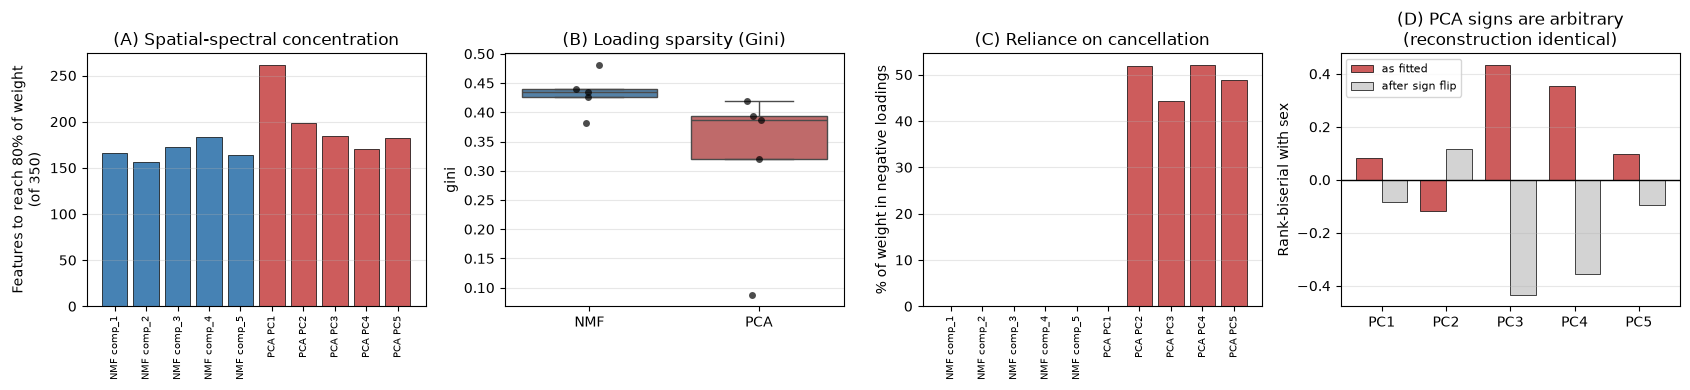

In [10]:
fig, axes = plt.subplots(1, 4, figsize=(17, 4))

ax = axes[0]
sub = conc_df.copy()
sub["label"] = sub["basis"] + " " + sub["component"]
ax.bar(sub["label"], sub["features_to_80pct"],
       color=["steelblue" if b == "NMF" else "indianred" for b in sub["basis"]],
       edgecolor="black", linewidth=0.5)
ax.set_ylabel(f"Features to reach 80% of weight\n(of {len(FEATURES)})")
ax.set_title("(A) Spatial-spectral concentration")
ax.tick_params(axis="x", rotation=90, labelsize=7)
ax.grid(alpha=0.3, axis="y")

ax = axes[1]
sns.boxplot(data=spars_df, x="basis", y="gini", ax=ax, showfliers=False,
            palette={"NMF": "steelblue", "PCA": "indianred"})
sns.stripplot(data=spars_df, x="basis", y="gini", ax=ax, color="black", alpha=0.7, size=5)
ax.set_title("(B) Loading sparsity (Gini)")
ax.set_xlabel("")
ax.grid(alpha=0.3, axis="y")

ax = axes[2]
sub = sign_df.copy()
sub["label"] = sub["basis"] + " " + sub["component"]
ax.bar(sub["label"], 100 * sub["negative_weight_share"],
       color=["steelblue" if b == "NMF" else "indianred" for b in sub["basis"]],
       edgecolor="black", linewidth=0.5)
ax.set_ylabel("% of weight in negative loadings")
ax.set_title("(C) Reliance on cancellation")
ax.tick_params(axis="x", rotation=90, labelsize=7)
ax.grid(alpha=0.3, axis="y")

ax = axes[3]
x = np.arange(len(PC_LABELS))
ax.bar(x - 0.2, flip_df["r_as_fitted"], width=0.4, label="as fitted",
       color="indianred", edgecolor="black", linewidth=0.5)
ax.bar(x + 0.2, flip_df["r_after_sign_flip"], width=0.4, label="after sign flip",
       color="lightgrey", edgecolor="black", linewidth=0.5)
ax.axhline(0, color="black", linewidth=1)
ax.set_xticks(x)
ax.set_xticklabels(PC_LABELS)
ax.set_ylabel("Rank-biserial with sex")
ax.set_title("(D) PCA signs are arbitrary\n(reconstruction identical)")
ax.legend(fontsize=8)
ax.grid(alpha=0.3, axis="y")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "nb17_fig_interpretability.png", dpi=300, bbox_inches="tight")
plt.show()

## Summary for the response letter

In [11]:
lines = []


def w(s=""):
    """Print and record a summary line."""
    print(s)
    lines.append(s)


w("=" * 72)
w("NOTEBOOK 17 SUMMARY - quantified interpretability, NMF against PCA (R1.7)")
w("=" * 72)
w(f"Both bases at k = {PUBLISHED_K} on the same {X.shape[0]} x {X.shape[1]} feature matrix.")
w("")
w("CONCENTRATION (features needed to reach a share of component weight)")
for share in MASS_SHARES:
    col = f"features_to_{int(share * 100)}pct"
    nmf_vals = conc_df[conc_df["basis"] == "NMF"][col]
    pca_vals = conc_df[conc_df["basis"] == "PCA"][col]
    w(f"  {int(share * 100)}%: NMF median {nmf_vals.median():.0f} "
      f"(range {nmf_vals.min():.0f}-{nmf_vals.max():.0f}), "
      f"PCA median {pca_vals.median():.0f} (range {pca_vals.min():.0f}-{pca_vals.max():.0f})")
for share in MASS_SHARES:
    col = f"channels_to_{int(share * 100)}pct"
    nmf_vals = conc_df[conc_df["basis"] == "NMF"][col]
    pca_vals = conc_df[conc_df["basis"] == "PCA"][col]
    w(f"  {int(share * 100)}% by channel (of {len(CHANNELS)}): NMF median "
      f"{nmf_vals.median():.0f}, PCA median {pca_vals.median():.0f}")
w("")
w("SPARSITY")
for basis in ("NMF", "PCA"):
    s = spars_df[spars_df["basis"] == basis]
    w(f"  {basis}: Gini median {s['gini'].median():.3f}, "
      f"normalised entropy median {s['normalised_entropy'].median():.3f}")
w("")
w("RELIANCE ON CANCELLATION")
w("  NMF: 0% of weight in negative loadings, by construction, for all five components")
for _, r in sign_df[sign_df["basis"] == "PCA"].iterrows():
    w(f"  {r['component']}: {100 * r['negative_weight_share']:.1f}% of weight negative "
      f"({int(r['n_negative_features'])} of {int(r['n_features'])} features)")
w("")
w("SIGN ARBITRARINESS (Part D)")
w(f"  Negating a principal component changes the reconstruction by at most "
  f"{flip_df['max_reconstruction_change'].max():.2e}")
w("  while reversing the sign of its reported sex association and leaving the p-value")
w("  identical. A claim about opposing directions is therefore not available in a signed")
w("  basis; under NMF the direction is fixed by the data.")
w("")
w("COST OF THE CONSTRAINT")
for _, r in cost_df.iterrows():
    w(f"  {r['basis']}: Frobenius error {r['frobenius_error']:.3f}, "
      f"variance explained {r['variance_explained']:.3f}")
w(f"  First principal component alone: {100 * pca.explained_variance_ratio_[0]:.1f}% of "
  "variance, no sex association")
w("")
w("=" * 72)

with open(OUTPUT_DIR / "nb17_summary.txt", "w", encoding="utf-8") as fh:
    fh.write("\n".join(lines) + "\n")
print()
print(f"Saved {OUTPUT_DIR / 'nb17_summary.txt'}")

NOTEBOOK 17 SUMMARY - quantified interpretability, NMF against PCA (R1.7)
Both bases at k = 5 on the same 86 x 350 feature matrix.

CONCENTRATION (features needed to reach a share of component weight)
  50%: NMF median 84 (range 75-94), PCA median 90 (range 85-154)
  80%: NMF median 166 (range 156-183), PCA median 185 (range 170-261)
  90%: NMF median 212 (range 197-229), PCA median 234 (range 218-302)
  50% by channel (of 14): NMF median 6, PCA median 7
  80% by channel (of 14): NMF median 10, PCA median 11
  90% by channel (of 14): NMF median 12, PCA median 13

SPARSITY
  NMF: Gini median 0.435, normalised entropy median 0.944
  PCA: Gini median 0.386, normalised entropy median 0.958

RELIANCE ON CANCELLATION
  NMF: 0% of weight in negative loadings, by construction, for all five components
  PC1: 0.0% of weight negative (0 of 350 features)
  PC2: 51.9% of weight negative (186 of 350 features)
  PC3: 44.3% of weight negative (149 of 350 features)
  PC4: 52.0% of weight negative (177 